# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [2]:
import numpy as np
import pandas as pd

# meting_nr: Nummer van de meting (1 t/m 18)
meting_nr = np.arange(1, 19)

# U_voeding: Gemeten bronspanning van de voeding in Volt (V)
U_voeding = np.array([
    17.9954, 16.9951, 15.9958, 14.9956, 13.9953,
    12.9951, 11.9956, 10.9958,  9.9956,  8.9954,
     7.9952,  6.9956,  5.9958,  4.9956,  3.9954,
     2.9952,  1.9956,  0.9958
])

# U_R1: Gemeten spanning over meetweerstand R1 (10 kΩ) in Volt (V)
U_R1 = np.array([
    1.11943, 1.03290, 0.94679, 0.86081, 0.77522,
    0.69046, 0.60615, 0.52288, 0.44062, 0.35961,
    0.28114, 0.20586, 0.13589, 0.074470, 0.029650,
    0.007568, 0.001385, 0.000181
])

metingen = pd.DataFrame({
    "Meting": meting_nr,
    "Spanning voeding (V)": U_voeding,
    "Spanning 10R1 (V)": U_R1
    
})
#Ruwe METINGEN
# Overgenomen uit het labjournaal (12 nov 2026). Eenheden: Ω, V, A, K.
import numpy as np
 
T_celsius = 23.0                 # kamertemperatuur, labjournaal
T = T_celsius + 273.15           # K (onzekerheid nog te bepalen)
q = -1.602e-19                   # C, negatieve elektronlading (handleiding)
n, u_n = 2.0, 0.1                # idealiteitsfactor Si (handleiding)
kB_datasheet = 1.380649e-23     # J/K
 
#Weerstanden op het bord, nominaal
labels = ["10 Ω", "100 Ω", "330 Ω (1 %)", "330 Ω (5 %)", "470 Ω",
          "1 kΩ", "4,7 kΩ", "10 kΩ (a)", "10 kΩ (b)", "33 kΩ"]
R_nom = np.array([10, 100, 330, 330, 470, 1e3, 4.7e3, 10e3, 10e3, 33e3])
 
# Weerstandsmetingen (Ω), per weerstand in de volgorde van `labels`
# 3½-DMM (Amprobe). Bij nr 5 en 6 stonden maar 2 cijfers (0,47 k en 0,99 k)
R_3half_kort = np.array([10.3, 99.8, 328.8, 325.4, 470, 990, 4700, 9990, 9970, 32970])  # nr 10: 32,97 of 32,47 kΩ? (5½ geeft 32,96)
R_3half_lang = np.array([10.4, 100.0, 328.8, 325.4, 470, 990, 4700, 9990, 9970, 32970])
 
# 5½-DMM. AANNAME: pagina "5½ DDM" (kleinere waarden) = korte snoeren,
# pagina "5,5 DDM" (waarden ~0,04 Ω hoger bij kleine R) = lange snoeren. Bevestigen!
R_5half_kort = np.array([10.062, 99.773, 328.96, 325.65, 468.68, 996.01, 4700.0, 9990.6, 9965.0, 32961])
R_5half_lang = np.array([10.101, 99.810, 329.00, 325.67, 468.71, 996.06, 4700.0, 9990.6, 9965.0, 32960])  # nr 3 t/m 6 handschrift ?
 
#Snoerweerstand 
R_snoer_kort = 0.03   # Ω, vul in
R_snoer_lang = 0.095   # Ω, vul in
 
# %% Spanningsdeler (5½-DMM)
# Welke weerstanden R1 en R2 het waren staat niet in het blad. De verhouding wijst op
# R1 ≈ 1 kΩ en R2 ≈ 330 Ω. Bevestigen!
U_B_deler = 19.9975   # V, voeding   # ? laatste cijfer
V_AB = 15.0315        # V, over R1
V_BC = 4.9649         # V, over R2
V_AC = 19.9971        # V, over R1 + R2
 
# %% Stroommetingen Amprobe (3½)
I_20V_40mA = 14.95e-3   # A, bereik 40m, voeding 20 V
U_B_20V    = 19.9975    # V (5½)
I_2V_40mA  = 1.49e-3    # A, bereik 40m, voeding 2 V
I_2V_4mA   = 1.402e-3   # A, bereik 4m, voeding 2 V
U_B_2V     = 1.99755    # V (5½)
 
# %% Diodemeting
# Schema: U_bron -> R2 -> (R1 + diode) parallel aan R3
R1_nom, R2_nom, R3_nom = 10e3, 1e3, 100.0
# TODO: NUMMER 9 GEBRUIKT
R1 = R_5half_kort[7]
R2 = R_5half_kort[5]
R3 = R_5half_kort[1]
 
U_bron = np.array([17.9954, 16.9951, 15.9958, 14.9956, 13.9953, 12.9951,
                   11.9950, 10.9958, 9.9956, 8.9954, 7.9952, 6.9950,
                   5.9958, 4.9956, 3.9954, 2.9952, 1.9950, 0.9958])   # V
U_R1 = np.array([1.11943, 1.03290, 0.94670, 0.86081, 0.77532, 0.69046,
                 0.60625, 0.52288, 0.44062, 0.35981, 0.28114, 0.20586,
                 0.13559, 0.074470, 0.029650, 0.007568, 0.001385, 0.000181])  # V
 
# Controle op lengtes
assert len(R_nom) == len(R_3half_kort) == len(R_3half_lang) == len(R_5half_kort) == len(R_5half_lang) == 10
assert len(U_bron) == len(U_R1) == 18
 
# %% Snelle controle
verschil_5half = R_5half_lang - R_5half_kort
verschil_3half = R_3half_lang - R_3half_kort


**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


Helling van het rechte deel: 19.68 1/V
Verzadigingsstroom (I_0):    4.21e-09 A
Berekende k_B:               1.365e-23 J/K


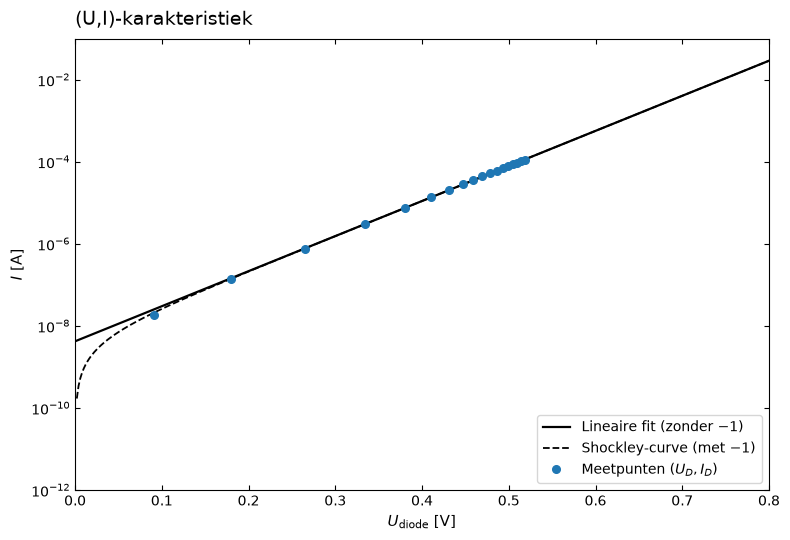

In [6]:
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import numpy as np
import astropy.constants as const
import astropy.units as u

# --- 1. CONSTANTEN EN EENHEDEN INSTELLEN ---
e = const.e.si.value        # Elementaire lading in Coulomb (C)
k_B_exact = const.k_B.si.value  # Exacte constante van Boltzmann in J/K
R1 = 9990.6              # Exacte waarde van je 10 kΩ meetweerstand in Ohm (Ω)
T = 298.15               # Kamertemperatuur in Kelvin (bijv. 20 °C = 293.15 K)
n = 2                # Idealiteitsfactor van de siliciumdiode

# U_D berekeningen
U = (R3/(R2+R3))*U_voeding
U_D= U - U_R1  # Spanning over de diode in Volt (V)

# Bijbehorende spanningen over R1 (in Volt) volgens de Shockley-vergelijking
I0_sim = 1.0e-10
helling_sim = e / (n * 1.380649e-23 * T)
U_R1shockley = R1 * I0_sim * (np.exp(helling_sim * U_D) - 1)

# --- 2. PROCESSING: Stroom en lineaire fit op het rechte deel ---
I_D = U_R1 / R1

# Fit ALLEEN het lineaire gebied (vanaf 0.30 V, waar de '-1' verwaarloosbaar is)
mask_lineair = U_D >= 0.30
helling, snijpunt = np.polyfit(U_D[mask_lineair], np.log(I_D[mask_lineair]), 1)

k_B_berekend = e / (n * T * helling)
I_0 = np.exp(snijpunt)

print(f"Helling van het rechte deel: {helling:.2f} 1/V")
print(f"Verzadigingsstroom (I_0):    {I_0:.2e} A")
print(f"Berekende k_B:               {k_B_berekend:.3e} J/K")

# --- 3. PLOTTEN: Exacte weergave zoals op de slide ---
U_lijn = np.linspace(0.0, 0.8, 400)
I_lineair_log = np.exp(helling * U_lijn + snijpunt)      # Rechte lijn (zonder -1)
I_exact = I_0 * (np.exp(helling * U_lijn) - 1)           # Shockley-curve (met -1)

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.semilogy(U_lijn, I_lineair_log, '-', color='black', linewidth=1.6, label='Lineaire fit (zonder $-1$)')
ax.semilogy(U_lijn[1:], I_exact[1:], '--', color='black', linewidth=1.3, label='Shockley-curve (met $-1$)')
ax.semilogy(U_D, I_D, 'o', color='tab:blue', markersize=5.5, label='Meetpunten $(U_D, I_D)$')

# Assen instellen
ax.set_title('(U,I)-karakteristiek', fontsize=14, loc='left', pad=10)
ax.set_xlabel(r'$U_{\mathrm{diode}}$ [V]', fontsize=11)
ax.set_ylabel(r'$I$ [A]', fontsize=11)

ax.set_xlim(0.0, 0.8)
ax.set_ylim(1e-12, 1e-1)
ax.set_xticks(np.arange(0.0, 0.81, 0.1))
ax.tick_params(direction='in', top=True, right=True, which='both')
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

In [7]:

# 1. Definieer het logaritmische model (zelfde vergelijking als een rechte lijn)
def log_shockley(U, log_I0, helling):
    return log_I0 + helling * U

# 2. Voer curve_fit uit op precies dezelfde gefilterde data als polyfit
popt, pcov = curve_fit(log_shockley, U_D[mask_lineair], np.log(I_D[mask_lineair]))

# 3. Haal de parameters eruit en reken terug naar I_0 en k_B
log_I0_cf, helling_cf = popt
I0_cf = np.exp(log_I0_cf)
k_B_cf = e / (n * T * helling_cf)

print(f"Helling curve_fit: {helling_cf:.2f} 1/V")
print(f"I_0 curve_fit:     {I0_cf:.2e} A")
print(f"k_B curve_fit:     {k_B_cf:.3e} J/K")
print(f"k_B exact:         {k_B_exact:.3e} J/K")

Helling curve_fit: 19.68 1/V
I_0 curve_fit:     4.21e-09 A
k_B curve_fit:     1.365e-23 J/K
k_B exact:         1.381e-23 J/K


In [8]:
#Data processing and analysis:
diff_pct = abs(k_B_berekend- k_B_exact) / k_B_exact * 100
print(f"{diff_pct:.2f}%")

diff_pct = abs(k_B_cf- k_B_exact) / k_B_exact * 100
print(f"{diff_pct:.2f}%")


1.12%
1.12%


**Describing the pattern in the processed data:**  


In [ ]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc